In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We propose a novel approach to the problem of ...,0.3259,0.0772,0.1981,0.8528,0.8088,0.8302,2,6,7,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,We propose a novel approach to the problem of ...,0.2812,0.0592,0.1587,0.8490,0.8044,0.8261,1,6,7,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,We present a new approach to the problem of ve...,0.1843,0.0465,0.1382,0.8227,0.8373,0.8299,1,3,4,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


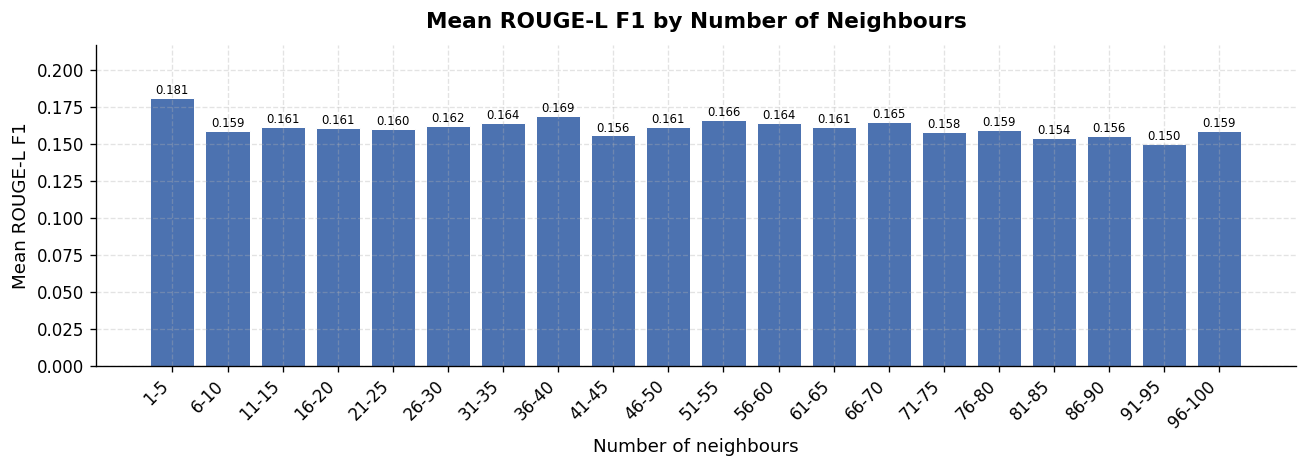

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

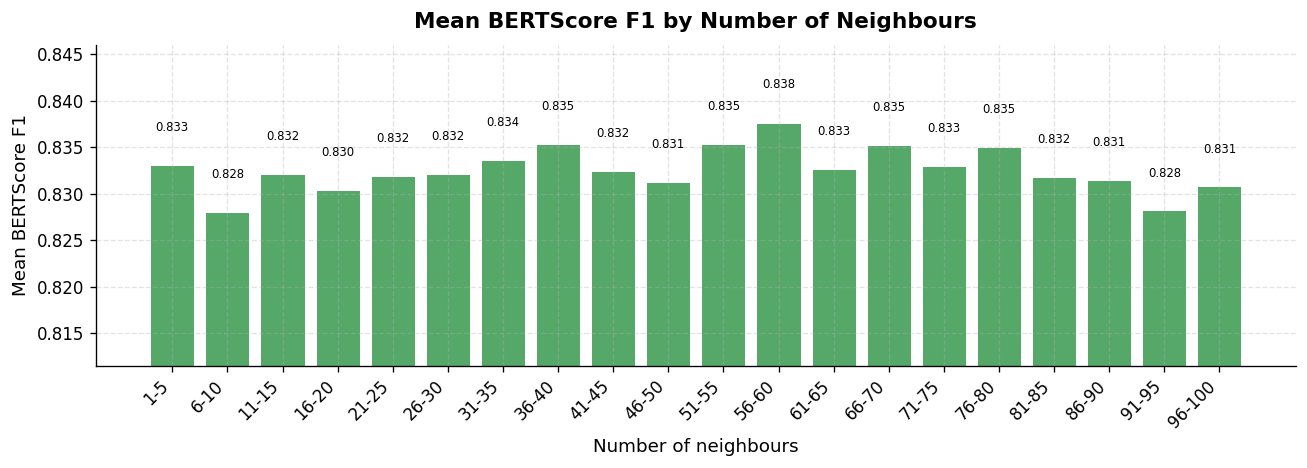

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

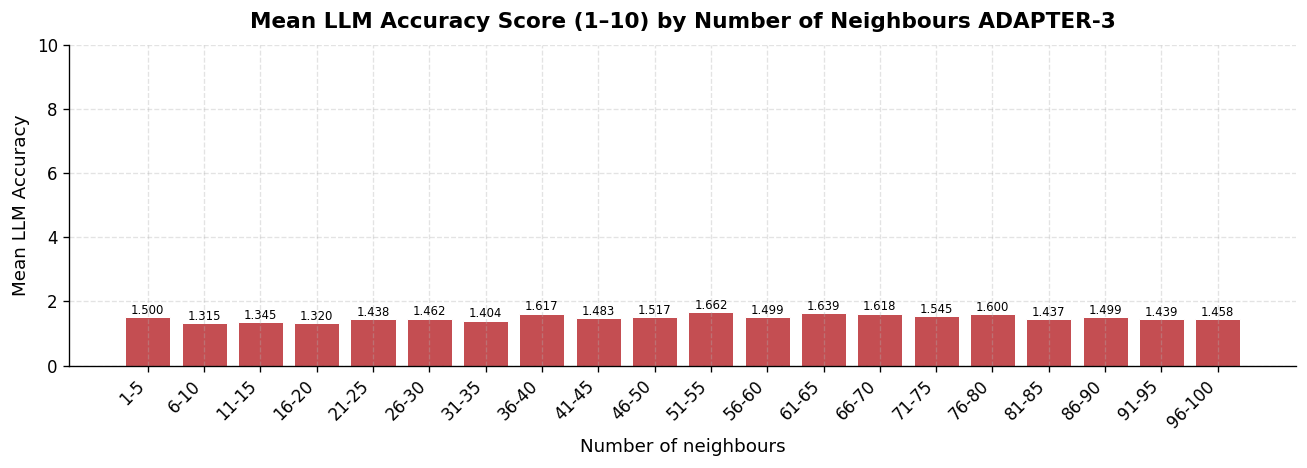

1.48994708994709
1.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

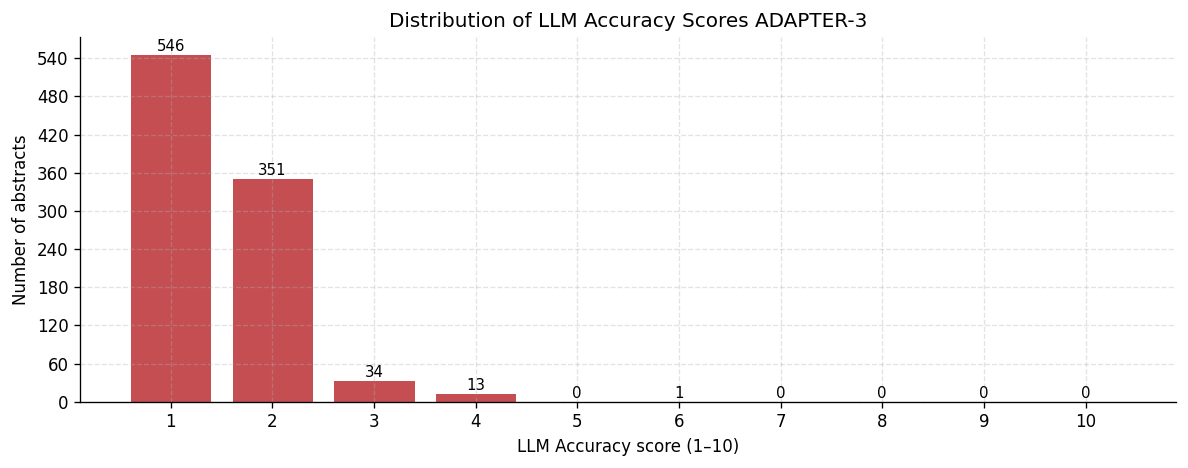

llm_accuracy
1     546
2     351
3      34
4      13
5       0
6       1
7       0
8       0
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

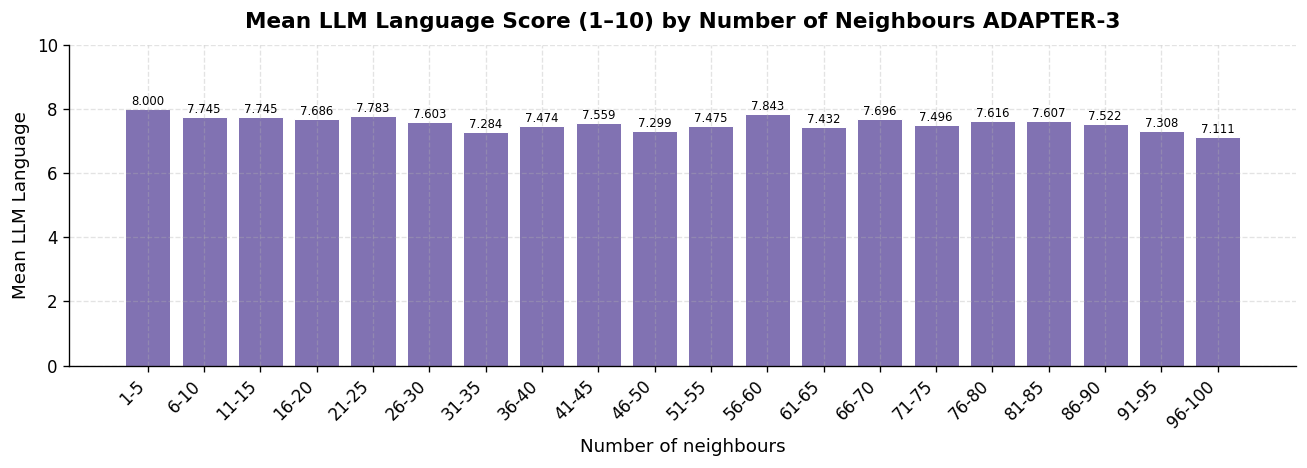

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

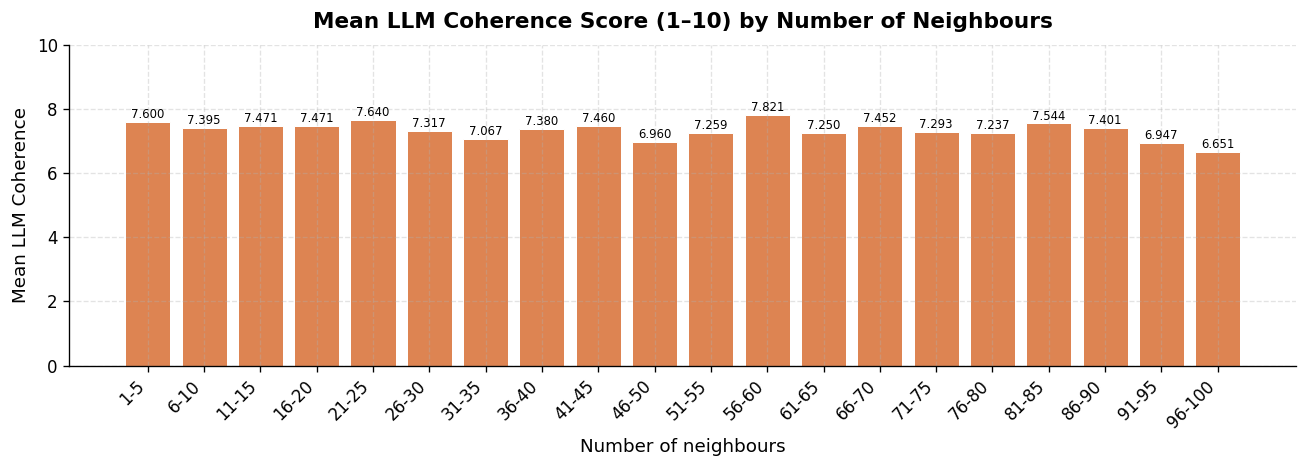

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

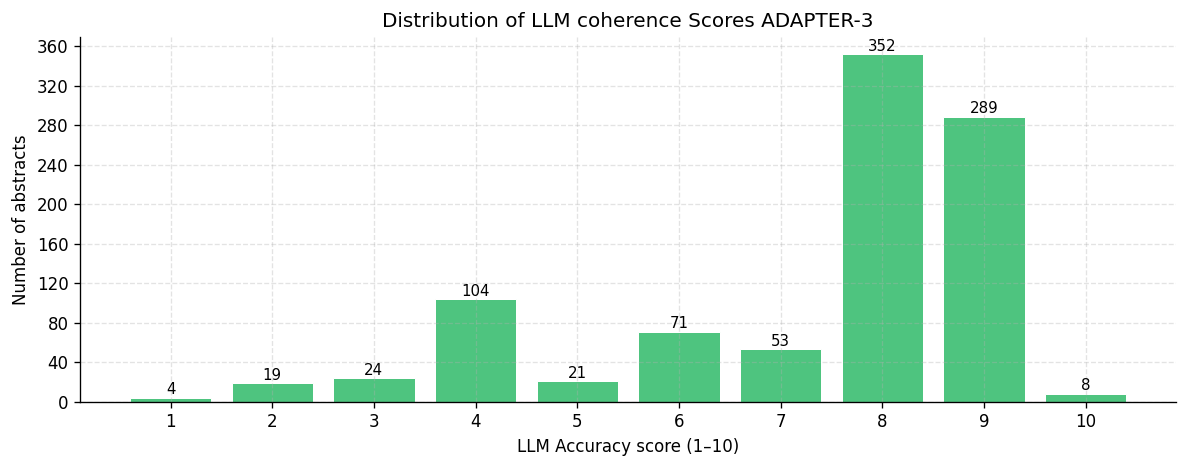

llm_coherence
1       4
2      19
3      24
4     104
5      21
6      71
7      53
8     352
9     289
10      8
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 23 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      1.4899
Mean llm_accuracy (excluding 1,2): 1.4989


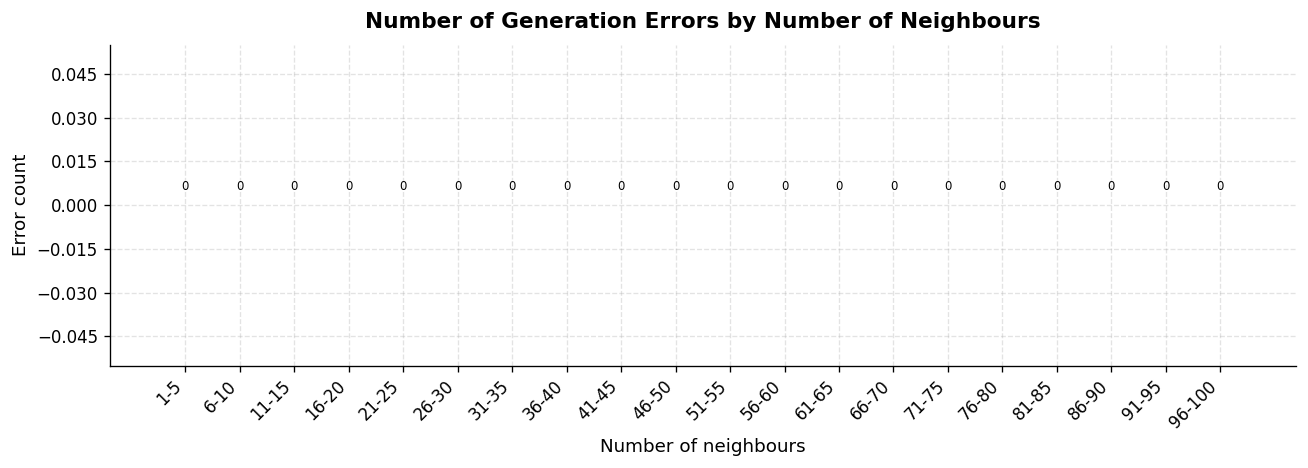

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_65797/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,151535,"The 5G networks have the capability to provide high compatibility for the new applications, industries, and business models. These networks can tremendously improve the quality of life by enabling various use cases that require high data rate, low latency, and continuous connectivity for applications pertaining to eHealth, automatic vehicles, smart cities, smart grid, and the Internet of Things (IoT). However, these applications need secure servicing as well as resource policing for effective network formations. There have been a lot of studies, which emphasized the security aspects of 5G networks while focusing only on the adaptability features of these networks. However, there is a gap in the literature which particularly needs to follow recent computing paradigms as alternative mechanisms for the enhancement of security. To cover this, a detailed description of the security for the 5G networks is presented in this article along with the discussions on the evolution of osmotic and catalytic computing based security modules. The taxonomy on the basis of security requirements is presented, which also includes the comparison of the existing state-of-the-art solutions. This article also provides a security model, “CATMOSIS,” which idealizes the incorporation of security features on the basis of catalytic and osmotic computing in the 5G networks. Finally, various security challenges and open issues are discussed to emphasize the works to follow in this direction of research.","In this paper, we study the problem of energy-efficient resource allocation in a multi-cell multi-user multiple-input multiple-output (MIMO) system. We consider a scenario where the base stations (BSs) are equipped with multiple antennas and the users are equipped with single antenna. We assume that the BSs are coordinated and share the channel state information (CSI) with each other. We consider a scenario where the BSs are equipped with multiple antennas and the users are equipped with single antenna. We assume that the BSs are coordinated and share the channel state information (CSI) with each other. We consider a scenario where the BSs are equipped with multiple antennas and the users are equipped with single antenna. We assume that the BSs are coordinated and share the channel state information (CSI) with each other. We consider a scenario where the BSs are equipped with multiple antennas and the users are equipped with single antenna. We assume that the BSs are coordinated and share the channel state information (CSI) with each other. We consider a scenario where the BSs are equipped with multiple antennas and the users are equipped with single antenna. We assume that the BSs are coordinated and share the channel state information (CSI) with each other. We consider a scenario where the BSs are equipped with multiple antennas and the users are equipped with single antenna. We assume that the BSs are coordinated and share the channel state information (CSI) with each other. We consider a scenario where the BSs are equipped with multiple antennas and the users are equipped with single antenna. We assume that the BSs are",1
1,51221,"Hyperspectral images (HSI) provide rich spectral information that contributed to the successful performance improvement of numerous computer vision tasks. However, it can only be achieved at the expense of images' spatial resolution. Hyperspectral image super-resolution (HSI-SR) addresses this problem by fusing low resolution (LR) HSI with multispectral image (MSI) carrying much higher spatial resolution (HR). All existing HSI-SR approaches require the LR HSI and HR MSI to be well registered and the reconstruction accuracy of the HR HSI relies heavily on the registration accuracy of different modalities. This paper exploits the uncharted problem domain of HSI-SR without the requirement of multi-modality registration. Given the unregistered LR HSI and HR MSI 

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_65797/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,85903,"In this paper, we study normalization methods for neural networks from the perspective of elimination singularity. Elimination singularities correspond to the points on the training trajectory where neurons become consistently deactivated. They cause degenerate manifolds in the loss landscape which will slow down training and harm model performances. We show that channel-based normalizations (e.g. Layer Normalization and Group Normalization) are unable to guarantee a far distance from elimination singularities, in contrast with Batch Normalization which by design avoids models from getting too close to them. To address this issue, we propose BatchChannel Normalization (BCN), which uses batch knowledge to avoid the elimination singularities in the training of channel-normalized models. Unlike Batch Normalization, BCN is able to run in both large-batch and micro-batch training settings. The effectiveness of BCN is verified on many tasks, including image classification, object detection, instance segmentation, and semantic segmentation. The code is here: this https URL.","We propose a novel approach to the problem of learning a deep neural network for image classification. Our approach is based on the observation that the training of a deep neural network is a non-convex optimization problem, and that the non-convexity is due to the non-linear activation functions. We propose to replace the non-linear activation functions with linear functions, and to train the resulting linear network. We show that the resulting linear network can be used to initialize the weights of a deep neural network, and that this initialization leads to a significant improvement in the performance of the deep neural network. We also show that the linear network can be used to initialize the weights of a deep neural network with different architecture. We show that the proposed approach is applicable to a wide range of deep neural networks, and that it leads to a significant improvement in the performance of the deep neural network.",1
1,96451,"Statistical generative models for molecular graphs attract attention from many researchers from the fields of bio- and chemo-informatics. Among these models, invertible flow-based approaches are not fully explored yet. In this paper, we propose a powerful invertible flow for molecular graphs, called graph residual flow (GRF). The GRF is based on residual flows, which are known for more flexible and complex non-linear mappings than traditional coupling flows. We theoretically derive non-trivial conditions such that GRF is invertible, and present a way of keeping the entire flows invertible throughout the training and sampling. Experimental results show that a generative model based on the proposed GRF achieves comparable generation performance, with much smaller number of trainable parameters compared to the existing flow-based model.","We propose a novel approach to the problem of learning a deep neural network from a small number of training samples. Our approach is based on the observation that the training samples are often related to each other, and that the network can be trained in a way that leverages this relationship. We propose a method that trains a network by first learning a representation of the training samples, and then training the network on this representation. We show that this approach can be used to train a network on a small number of samples, and that it can be used to train a network on a large number of samples. We also show that this approach can be used to train a network on a small number of samples, and that it can be used to train a network on a large number of samples.",1
2,134891,"An increasing number of works in natural language processing have addressed the effect of bias on the predicted outcomes, introducing mitigation techniques that act on different parts of the standard NLP pipeline (data and models). However,

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


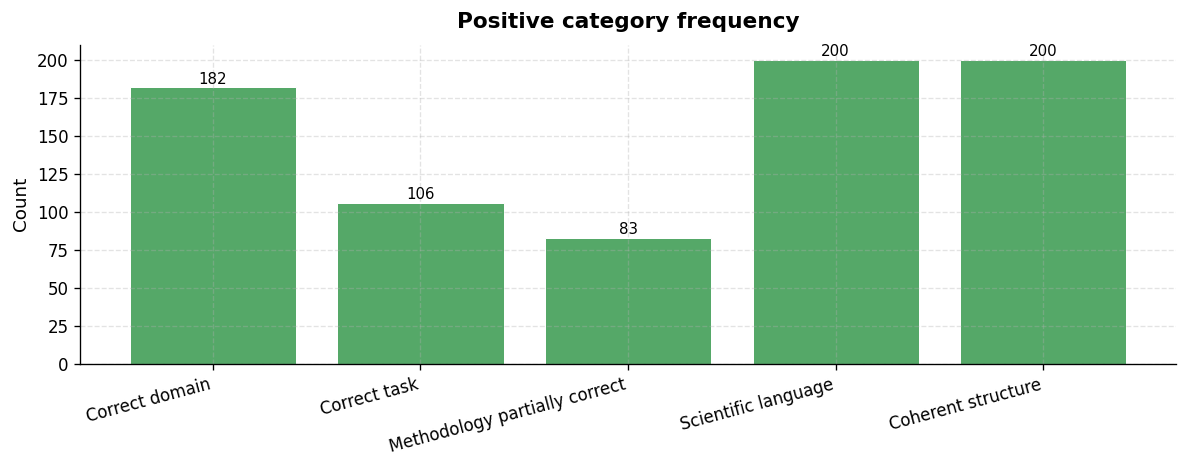

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()